# 07 · Gradient Boosting with XGBoost (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (regression, ឯកតា $100,000)

## 1. Goal
សាកល្បង **Gradient Boosting** ដែលជា model ខ្លាំងបំផុតមួយសម្រាប់ tabular data។ យើងប្រើ `XGBRegressor` ហើយ tune វាដោយ `RandomizedSearchCV` លើ training set តែប៉ុណ្ណោះ។

## Concept
**Random Forest** (Lesson 5) សាង trees ជ្រៅជាច្រើន **ស្របគ្នា ហើយឯករាជ្យ** រួចយកមធ្យម (បន្ថយ variance)។
**Boosting** សាង trees តូចៗ **មួយបន្ទាប់ពីមួយ** ដែលនីមួយៗរៀន **កែកំហុស** របស់ trees ទាំងអស់មុនវា (បន្ថយ bias មួយជំហានម្តងៗ):

1. ទាយដំបូង: តម្លៃមធ្យមសម្រាប់គ្រប់គ្នា។
2. គណនា **residual** = actual − predicted ។
3. Train tree តូចមួយ **ដើម្បីទាយ residual ទាំងនោះ**។
4. បូក tree ថ្មីចូល (គុណនឹង `learning_rate`) ហើយធ្វើម្តងទៀត។

**ឧបមា "លេងហ្គោលហ្វ":** វាយចូលដំបូងទៅជិតរន្ធ។ ការវាយបន្ទាប់មិនព្យាយាមវាយពីដើមទេ ប៉ុន្តែវាយ **ចម្ងាយដែលនៅសល់** (កំហុស)។ ការវាយតូចៗម្តងហើយម្តងទៀត
ជិតរន្ធជាងការវាយខ្លាំងម្តងតែមួយ។ ដូច្នេះ `learning_rate` តូច (ជំហានតូច) ត្រូវការ trees ច្រើនជាង ប៉ុន្តែជាធម្មតាចុងក្រោយល្អជាង។

**Hyperparameters សំខាន់:** `n_estimators` (ចំនួន trees), `learning_rate`, `max_depth` (tree ស្រាល = 3–8), `subsample`/`colsample_bytree` (ចៃដន្យដូច forest), `min_child_weight`, `reg_lambda` (L2 regularization ដូច Ridge)។
**គ្រោះថ្នាក់:** trees ច្រើនពេក → **overfit** (train error ធ្លាក់ទៅ ខណៈ validation error ឈប់ប្រសើរ)។ ដំណោះស្រាយ: **early stopping** (ឈប់ពេល validation score មិនប្រសើរ) ឬ tune `n_estimators` ដោយ CV។

Import libraries។

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import loguniform, randint, uniform
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from xgboost import XGBRegressor

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

def evaluate(model, A, B):
    """Train and test MAE / RMSE / R2 for a fitted model. A = train features, B = test features."""
    out = {}
    for split, Xs, ys in [("train", A, y_train), ("test", B, y_test)]:
        pred = model.predict(Xs)
        out[f"{split} MAE"] = mean_absolute_error(ys, pred)
        out[f"{split} RMSE"] = np.sqrt(mean_squared_error(ys, pred))
        out[f"{split} R2"] = r2_score(ys, pred)
    return out

Load clean data ហើយ split ដូច Lesson 2 (`test_size=0.2`, `random_state=42`)។ XGBoost ដូច trees ផ្សេងទៀត **មិនត្រូវការ scaling** ហើយ data នេះគ្មាន missing/categorical ដូច្នេះប្រើ `X_train` ដោយផ្ទាល់។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = X.columns.tolist()
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 2. Boosting step by step: 1, 2, 5, 50 trees
ដើម្បីមើលដោយភ្នែក ប្រើ feature តែមួយ (`MedInc`)។ Trees តូចខ្លាំង (`max_depth=2`) ហើយ `learning_rate=0.3`។ សង្កេតមើលខ្សែកោងដែល model សាងឡើងបន្តិចម្តងៗ។

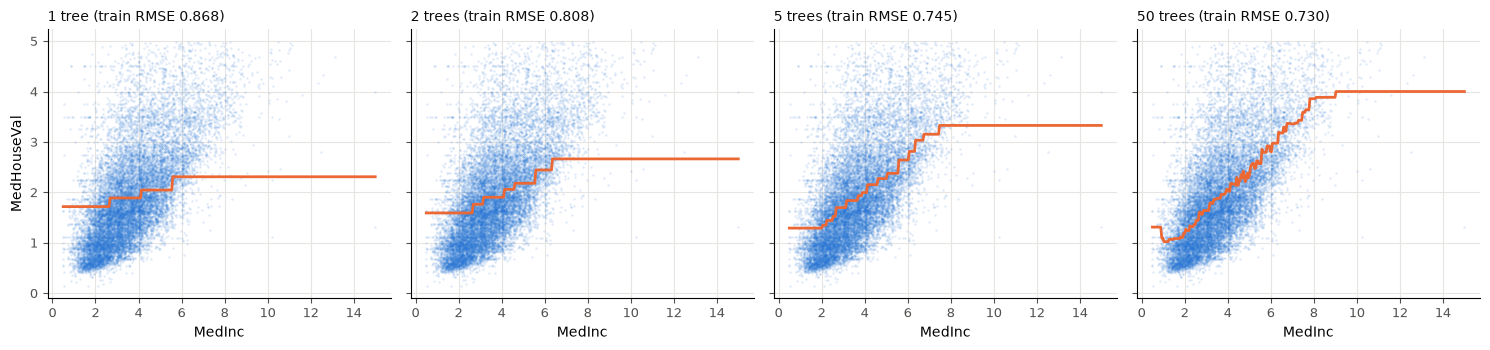

In [3]:
x1 = X_train[["MedInc"]]
grid = pd.DataFrame({"MedInc": np.linspace(x1["MedInc"].min(), x1["MedInc"].max(), 300)})

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, n in zip(axes, [1, 2, 5, 50]):
    m = XGBRegressor(n_estimators=n, max_depth=2, learning_rate=0.3, random_state=42).fit(x1, y_train)
    rmse = np.sqrt(mean_squared_error(y_train, m.predict(x1)))
    ax.scatter(x1["MedInc"], y_train, s=3, color=BLUE, alpha=0.15, linewidth=0)
    ax.plot(grid["MedInc"], m.predict(grid), color=ORANGE, linewidth=2)
    ax.set_title(f"{n} tree{'s' if n > 1 else ''} (train RMSE {rmse:.3f})", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("MedInc"); style(ax)
axes[0].set_ylabel("MedHouseVal")
fig.tight_layout()
plt.show()

**អានក្រាហ្វ:**
- **1 tree** (`max_depth=2`): ជាជណ្តើរតិចតួចតែប៉ុន្មានកម្រិត (train RMSE 0.868)។ វាចាប់បានទិសដៅ (ចំណូលខ្ពស់ → តម្លៃខ្ពស់) ប៉ុន្តែរដុបណាស់។
- **2 trees** (0.808) និង **5 trees** (0.745): tree នីមួយៗថ្មីបន្ថែម **ជណ្តើរតូចៗ** ដើម្បីកែកំហុសដែលនៅសល់ ហើយខ្សែកោងចាប់ផ្តើមតាមទម្រង់នៃ data កាន់តែល្អ។
- **50 trees** (0.730): ខ្សែកោងតាមទម្រង់ data យ៉ាងល្អ (រួមទាំងវាស្ទើរតែរាបស្មើនៅ `MedInc` > 8 ដែលមាន rows តិច)។
- ការប្រសើរឡើងថយចុះបន្តិចម្តងៗ: ពី 1 ទៅ 5 trees RMSE ធ្លាក់ 0.12 ប៉ុន្តែពី 5 ទៅ 50 trees ធ្លាក់ត្រឹម 0.015។ ជាមួយ feature **តែមួយ** RMSE មិនអាចទាបជាង ≈ 0.73 ទេ ព្រោះចំណូលតែមួយមិនពន្យល់តម្លៃបានគ្រប់គ្រាន់
  (ត្រូវការទីតាំង)។ Model ពេញលេញនឹងប្រើ features ទាំង 8។

## 3. Default XGBRegressor
Features ទាំង 8 ជាមួយ hyperparameters លំនាំដើម: `n_estimators=100`, `learning_rate=0.3`, `max_depth=6`។

In [4]:
xgb_default = XGBRegressor(random_state=42, n_jobs=-1).fit(X_train, y_train)
pd.DataFrame({"XGBRegressor (default)": evaluate(xgb_default, X_train, X_test)}).T.round(3)

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
XGBRegressor (default),0.176,0.245,0.936,0.283,0.421,0.815


**អានលទ្ធផល:** XGBoost លំនាំដើម (មិនទាន់ tune) ទទួលបាន test **MAE 0.283, RMSE 0.421, R² 0.815**: ឈ្នះ Random Forest ដែលបាន tune (R² 0.797) រួចទៅហើយ។
ប៉ុន្តែ train R² 0.936 ខ្ពស់ជាង test 0.815 ច្រើន ដូច្នេះមានចន្លោះសម្រាប់ tuning ដើម្បីកាត់បន្ថយ overfit។

## 4. Early stopping
ដោយ trees ច្រើនពេកអាច overfit យើងត្រូវការវិធីដឹងថា **ឈប់ពេលណា**។ ដាក់ទុក 20% នៃ **training set** ជា validation set (មិនមែន test set!)។
Train ជា 80% ហើយតាមដាន RMSE លើទាំងពីរ។ `early_stopping_rounds=30` ឈប់ពេល validation RMSE មិនប្រសើរឡើងក្នុង 30 rounds ជាប់គ្នា។
ប្រើ `learning_rate=0.3` ដើម្បីមើល overfit ឲ្យឆាប់។

In [5]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)
xgb_es = XGBRegressor(n_estimators=1000, learning_rate=0.3, max_depth=6, early_stopping_rounds=30,
                      eval_metric="rmse", random_state=42, n_jobs=-1)
xgb_es.fit(X_fit, y_fit, eval_set=[(X_fit, y_fit), (X_val, y_val)], verbose=False)
history = xgb_es.evals_result()
{"best_iteration (0-based)": int(xgb_es.best_iteration), "trees actually trained": len(history["validation_1"]["rmse"]),
 "best validation RMSE": round(float(min(history["validation_1"]["rmse"])), 4),
 "train RMSE at the end": round(float(history["validation_0"]["rmse"][-1]), 4),
 "validation RMSE at the end": round(float(history["validation_1"]["rmse"][-1]), 4)}

{'best_iteration (0-based)': 162,
 'trees actually trained': 193,
 'best validation RMSE': 0.4281,
 'train RMSE at the end': 0.1544,
 'validation RMSE at the end': 0.4294}

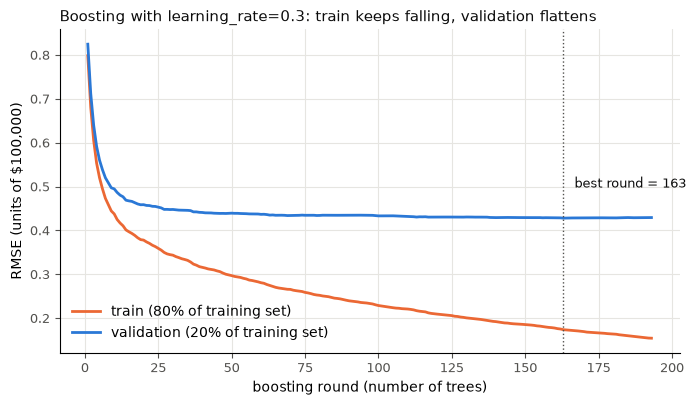

In [6]:
rounds = np.arange(1, len(history["validation_0"]["rmse"]) + 1)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(rounds, history["validation_0"]["rmse"], color=ORANGE, linewidth=2, label="train (80% of training set)")
ax.plot(rounds, history["validation_1"]["rmse"], color=BLUE, linewidth=2, label="validation (20% of training set)")
ax.axvline(xgb_es.best_iteration + 1, color=MUTED, linewidth=1, linestyle=":")
ax.annotate(f"best round = {xgb_es.best_iteration + 1}", (xgb_es.best_iteration + 1, min(history["validation_1"]["rmse"])),
            xytext=(8, 22), textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel("boosting round (number of trees)"); ax.set_ylabel("RMSE (units of $100,000)")
ax.set_title("Boosting with learning_rate=0.3: train keeps falling, validation flattens", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False); style(ax)
plt.show()

**អានក្រាហ្វ:**
- **ទាំងពីរធ្លាក់ចុះលឿននៅដើម** (validation RMSE 0.83 → ≈ 0.47 ក្នុង 15 rounds ដំបូង)។ បន្ទាប់មក **validation RMSE រាបស្មើ** (≈ 0.44 នៅ round 50, 0.4281 នៅ round 163) ខណៈ **train RMSE បន្តធ្លាក់** ទៅ 0.154។
- **គម្លាតរវាង train និង validation** កើនឡើងជានិច្ច (0.154 ទល់ 0.429) = **Overfitting** កាន់តែខ្លាំង។ Trees បន្ថែមទៅ train បានតែដោយទន្ទេញ noise ហើយមិនជួយ validation ទេ។
- `early_stopping_rounds=30` ឈប់ត្រូវបាន train ត្រឹម **193 trees** (best round 163 + 30)។ ក្នុងករណីនេះ validation RMSE ឈប់ប្រសើរតិចតួច ដូច្នេះ trees បន្ថែមមិនបង្ក្រោះថ្នាក់ច្រើនទេ ប៉ុន្តែក៏មិនជួយដែរ។
  ជាមួយ `learning_rate` ធំ (0.3) model ទៅដល់កម្រិតរាបស្មើលឿន។ `learning_rate` តូចជាងត្រូវការ trees ច្រើនជាង ប៉ុន្តែជារឿយៗល្អជាងនៅចុងក្រោយ។
- Early stopping ប្រើ **validation set ដែលកាត់ពី training set** (មិនមែន test set) ដូច្នេះ test set នៅតែស្អាត។

## 5. Tune with RandomizedSearchCV (training set only)
`GridSearchCV` សាកល្បងគ្រប់បន្សំ (យឺតពេលមាន hyperparameters 7)។ `RandomizedSearchCV` សាកល្បង **30 បន្សំចៃដន្យ** ពី distributions ហើយជាធម្មតារកបាន setting ស្ទើរតែល្អស្មើគ្នាក្នុងរយៈពេលតិចជាង។
- `loguniform`: សមរម្យសម្រាប់ `learning_rate` ព្រោះវាសាកល្បងតម្លៃតូច (0.01–0.03) និងធំ (0.1–0.3) ស្មើគ្នា។
- Cross-Validation 3-fold លើ **training set តែប៉ុណ្ណោះ**; test set មិនត្រូវបានប៉ះ។

In [7]:
param_dist = {
    "n_estimators": randint(200, 1001),
    "learning_rate": loguniform(0.01, 0.3),
    "max_depth": randint(3, 9),
    "min_child_weight": randint(1, 11),
    "subsample": uniform(0.6, 0.4),            # 0.6 .. 1.0
    "colsample_bytree": uniform(0.6, 0.4),     # 0.6 .. 1.0
    "reg_lambda": loguniform(0.5, 10),
}
cv3 = KFold(n_splits=3, shuffle=True, random_state=42)
search = RandomizedSearchCV(XGBRegressor(random_state=42, n_jobs=1), param_dist, n_iter=30, cv=cv3,
                            scoring="neg_root_mean_squared_error", random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
{k: (int(v) if isinstance(v, (int, np.integer)) else round(float(v), 4)) for k, v in search.best_params_.items()}

{'colsample_bytree': 0.64,
 'learning_rate': 0.0477,
 'max_depth': 7,
 'min_child_weight': 4,
 'n_estimators': 863,
 'reg_lambda': 3.5139,
 'subsample': 0.6226}

10 បន្សំល្អបំផុតពី 30 (CV RMSE: ទាបជាង = ល្អជាង)។

In [8]:
results = pd.DataFrame(search.cv_results_)
results["CV RMSE"] = -results["mean_test_score"]
cols = ["CV RMSE", "std_test_score", "param_n_estimators", "param_learning_rate", "param_max_depth",
        "param_min_child_weight", "param_subsample", "param_colsample_bytree", "param_reg_lambda"]
top = results.sort_values("CV RMSE").head(10)[cols].rename(columns=lambda c: c.replace("param_", ""))
top.round(4).reset_index(drop=True)

,CV RMSE,std_test_score,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,reg_lambda
0,0.4056,0.0054,863,0.0477,7,4,0.6226,0.6400,3.5139
1,0.4058,0.0060,883,0.0288,7,3,0.9549,0.6254,3.3764
2,0.4076,0.0048,968,0.0150,8,3,0.6944,0.7889,4.3447
3,0.4090,0.0056,584,0.0336,8,1,0.7708,0.6488,0.9897
4,0.4094,0.0053,606,0.0679,6,5,0.8159,0.7901,3.0573
5,0.4126,0.0041,443,0.0819,6,7,0.6186,0.6362,2.9493
6,0.4131,0.0050,400,0.0916,6,7,0.7324,0.9705,3.2352
7,0.4135,0.0056,871,0.0315,5,6,0.8812,0.6479,2.3656
8,0.4137,0.0027,401,0.1755,6,2,0.8392,0.6125,7.2974
9,0.4151,0.0047,545,0.0303,6,3,0.6906,0.9433,2.3186


ប្រៀបធៀប CV RMSE ជាមួយ **default** (KFold 3 ដដែល) ដើម្បីដឹងថាការ tune ជួយប៉ុន្មាន។

In [9]:
default_cv = -cross_val_score(XGBRegressor(random_state=42, n_jobs=-1), X_train, y_train, cv=cv3,
                              scoring="neg_root_mean_squared_error")
{"default CV RMSE": round(float(default_cv.mean()), 4), "default std": round(float(default_cv.std()), 4),
 "tuned CV RMSE": round(float(-search.best_score_), 4),
 "tuned std": round(float(results.loc[search.best_index_, "std_test_score"]), 4),
 "gain": f"{(1 - (-search.best_score_) / default_cv.mean()) * 100:.1f}%"}

{'default CV RMSE': 0.4318,
 'default std': 0.0042,
 'tuned CV RMSE': 0.4056,
 'tuned std': 0.0054,
 'gain': '6.1%'}

**អានលទ្ធផល:**
- **CV RMSE បន្ទាប់ពី tune: 0.4056 ទល់ 0.4318 (default)** = ប្រសើរឡើង **6.1%**។ ការ tune ជួយពិតប្រាកដ ប៉ុន្តែមិនមែនបដិវត្តន៍ទេ: default ល្អរួចហើយ។
- **Hyperparameters ល្អបំផុត:** `n_estimators=863`, `learning_rate≈0.048`, `max_depth=7`, `min_child_weight=4`, `subsample≈0.62`, `colsample_bytree≈0.64`, `reg_lambda≈3.5`។
- **លំនាំរបស់បន្សំល្អបំផុត 10:** `learning_rate` តូច (0.015–0.18, ភាគច្រើន < 0.1) ជាមួយ **trees ច្រើន** (400–970): ជំហានតូចៗ ដូចមេរៀនហ្គោលហ្វ។ `max_depth` 5–8 (ជ្រៅជាងលំនាំដើមមួយពីរកម្រិតបន្តិច) ហើយ **`subsample` និង `colsample_bytree` < 1** (ចៃដន្យដូច forest ជួយបន្ថយ variance)។ `reg_lambda` ភាគច្រើន > 2 (regularization ខ្លាំងជាងលំនាំដើម 1)។
- **10 បន្សំកំពូលមានពិន្ទុស្រដៀងគ្នាខ្លាំង** (0.4056–0.4151) ហើយ std ក្នុងចន្លោះ folds ≈ 0.005 ធំជាងភាពខុសគ្នារវាង 5 បន្សំដំបូង (0.4056–0.4094)។ ដូច្នេះ **មិនមានបន្សំវេទមន្តតែមួយទេ**: មានតំបន់ធំទូលាយនៃ settings ល្អ ហើយ model មិនផុយស្រួយចំពោះ hyperparameters។
- ⚠️ ពិន្ទុ CV របស់អ្នកឈ្នះ (0.4056) ស្ថិតក្នុងភាពសុទិដ្ឋិនិយមតិចតួច ព្រោះវាត្រូវបានជ្រើសពី 30 ដងលើ folds ដូចគ្នា។ ការវាយតម្លៃដ៏ស្មោះត្រង់គឺលើ test set ដែលយើងមិនទាន់ប៉ះ។

## 6. Final model on the test set
`search.best_estimator_` ត្រូវបាន train ឡើងវិញលើ training set ទាំងមូលជាមួយ hyperparameters ល្អបំផុត។ ឥឡូវនេះ **បើក test set ម្តង**។

In [10]:
xgb = search.best_estimator_
pd.DataFrame({"XGBRegressor (default)": evaluate(xgb_default, X_train, X_test),
              "XGBRegressor (tuned)": evaluate(xgb, X_train, X_test)}).T.round(3)

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
XGBRegressor (default),0.176,0.245,0.936,0.283,0.421,0.815
XGBRegressor (tuned),0.126,0.178,0.966,0.264,0.399,0.834


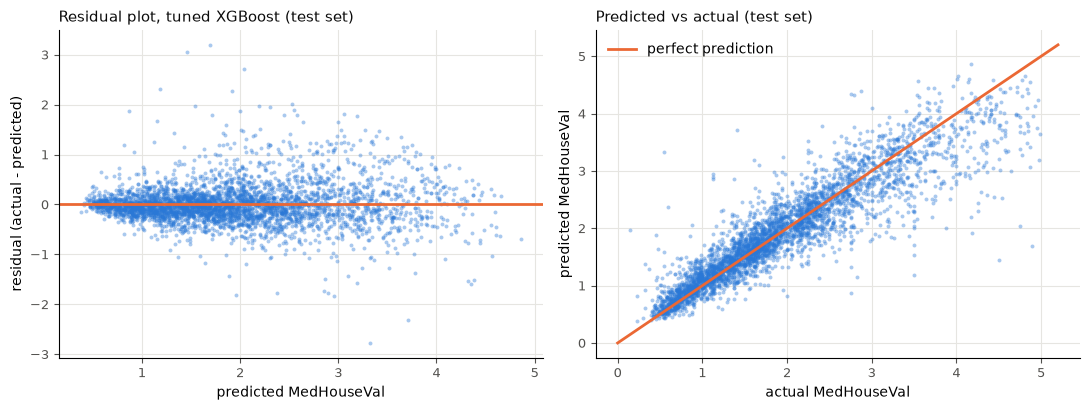

In [11]:
pred_test = xgb.predict(X_test)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residual plot, tuned XGBoost (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [0, 5.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

**អានលទ្ធផល:** XGBoost tuned: **test MAE 0.264, RMSE 0.399, R² 0.834**។ ល្អជាង default (0.283 / 0.421 / 0.815) ហើយល្អជាង Random Forest (0.295 / 0.441 / 0.797) និង SVR (0.328 / 0.477 / 0.762)។
- **Test RMSE (0.399) ជិត CV RMSE (0.4056)**: Cross-Validation ផ្តល់ការព្យាករដ៏ស្មោះត្រង់អំពីលទ្ធផលប្រឡង។ (Test ល្អជាងបន្តិចព្រោះ model ចុងក្រោយ train លើ rows ទាំងអស់ ចំណែក CV train លើតែ 2/3។)
- **Train R² 0.966 ទល់ test 0.834**: នៅមានគម្លាត (overfit ខ្លះ) ប៉ុន្តែដូច forest, test score ទើបជាអ្វីដែលសំខាន់។
- **Predicted vs actual:** ពពកចំណុចតឹងជាង Lessons មុនៗ។ សម្រាប់សង្កាត់ថ្លៃបំផុត (actual > 4) ចំណុចនៅតែភាគច្រើនក្រោមបន្ទាត់ ប៉ុន្តែតិចជាង Linear/KNN/forest។ **Residual plot** នៅតែមានរាងចីវលោ (កំហុសធំជាងសម្រាប់តម្លៃខ្ពស់) ដែលជាលក្ខណៈនៃ data នេះ: សង្កាត់ថ្លៃមានតម្លៃពិតរាយប៉ាយច្រើន។

## 7. Permutation importance (test set)
កូរតម្លៃរបស់ feature មួយលើ **test set** ហើយមើលថា R² ធ្លាក់ប៉ុន្មាន។ វាជាវិធីជឿជាក់ជាង `feature_importances_` (impurity/gain) ដែលវាស់លើ training។

In [12]:
perm = permutation_importance(xgb, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({"R2 drop": perm.importances_mean, "std": perm.importances_std,
                           "XGBoost gain importance": xgb.feature_importances_},
                          index=feature_names).sort_values("R2 drop", ascending=False)
importance.round(3)

,R2 drop,std,XGBoost gain importance
Latitude,1.173,0.017,0.165
Longitude,1.042,0.014,0.147
MedInc,0.279,0.006,0.341
AveOccup,0.146,0.007,0.111
AveRooms,0.086,0.004,0.087
HouseAge,0.042,0.002,0.068
Population,0.011,0.002,0.035
AveBedrms,0.009,0.001,0.045


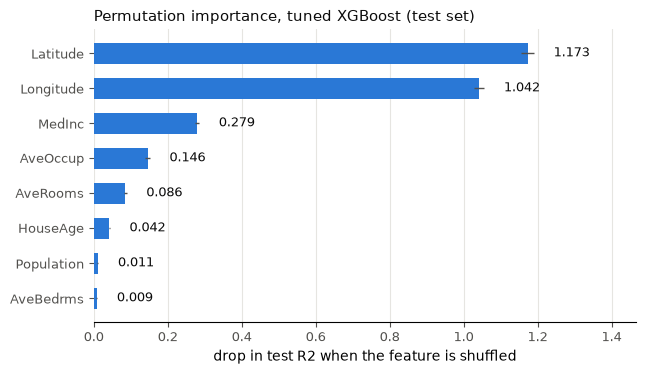

In [13]:
used = importance["R2 drop"].sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.barh(used.index, used.values, xerr=importance.loc[used.index, "std"], color=BLUE, height=0.6,
               error_kw={"ecolor": MUTED, "elinewidth": 1})
ax.bar_label(bars, fmt="%.3f", padding=14, color=INK, fontsize=9)
ax.set_xlabel("drop in test R2 when the feature is shuffled")
ax.set_title("Permutation importance, tuned XGBoost (test set)", loc="left", fontsize=11, color=INK)
ax.set_xlim(0, used.max() * 1.25)
ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors=MUTED, labelsize=9)
plt.show()

**អានលទ្ធផល:**
- ខុសពី Random Forest (Lesson 5: `MedInc` 0.60, `Latitude` 0.455, `Longitude` 0.377), XGBoost ដែលបាន tune ពឹងលើ **ទីតាំង** ខ្លាំងជាង: ការកូរ `Latitude` ធ្វើឲ្យ test R² ធ្លាក់ **1.17** (ពី 0.83 ទៅ ≈ −0.34) និង `Longitude` ធ្លាក់ 1.04។ `MedInc` ធ្លាក់ 0.28។ `AveOccup` 0.146, `AveRooms` 0.086, `HouseAge` 0.042, `Population` 0.011, `AveBedrms` 0.009។
- ⚠️ **ត្រូវប្រយ័ត្ន:** `Latitude` និង `Longitude` ទាក់ទងគ្នាខ្លាំង (≈ −0.93)។ ការកូរតែមួយក្នុងចំណោមវា បង្កើតទីតាំង **មិនអាចកើតមាន** (ឧ. កូអរដោណេនៅក្នុងមហាសមុទ្រ ឬខាងក្រៅរដ្ឋ) ដែល model មិនធ្លាប់ឃើញ។ ដូច្នេះ R² ធ្លាក់ខ្លាំង **លើសពីតម្លៃពិតនៃ feature នោះតែឯង**។
  គួរអានទាំងពីរជា **គូ**: ទីតាំងសំខាន់ណាស់ ប៉ុន្តែលេខ 1.17 និង 1.04 មិនគួរត្រូវបានយកជា "ភាគរយនៃ importance" ទេ។
- **`XGBoost gain importance`** (ពី training) ផ្តល់ចំណាត់ថ្នាក់ **ផ្សេង**: `MedInc` 0.341 ជាប់ទី 1, `Latitude` 0.165, `Longitude` 0.147។ វិធីផ្សេងៗនៃការវាស់ importance អាចមិនយល់ស្របគ្នា ជាពិសេសពេល features ទាក់ទងគ្នា។ **កុំជឿ importance តែមួយប្រភេទ។**
- Features ទាំងបីប្រភេទយល់ស្របគ្នាលើ: `MedInc` និងទីតាំងសំខាន់បំផុត; `Population` និង `AveBedrms` សំខាន់តិចបំផុត។

## 8. Comparison with earlier models
Split ដដែល។ Linear Regression, KNN និង SVR ប្រើ scaling (fit លើ train តែប៉ុណ្ណោះ)។ SVR ប្រើ hyperparameters ពី Lesson 6 (`C=3`, `gamma=0.3`)។ Random Forest ប្រើ `max_features=0.5` ពី Lesson 5។

In [14]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
forest = RandomForestRegressor(n_estimators=300, max_features=0.5, random_state=42, n_jobs=-1).fit(X_train, y_train)
svr = Pipeline([("scaler", StandardScaler()), ("svr", SVR(C=3, gamma=0.3))]).fit(X_train, y_train)

comparison = pd.DataFrame({
    "Baseline (mean)": evaluate(DummyRegressor(strategy="mean").fit(X_train_s, y_train), X_train_s, X_test_s),
    "Linear Regression": evaluate(LinearRegression().fit(X_train_s, y_train), X_train_s, X_test_s),
    "KNN (k=15)": evaluate(KNeighborsRegressor(n_neighbors=15).fit(X_train_s, y_train), X_train_s, X_test_s),
    "Tree (max_depth=9)": evaluate(DecisionTreeRegressor(max_depth=9, random_state=42).fit(X_train, y_train), X_train, X_test),
    "Random Forest (300 trees)": evaluate(forest, X_train, X_test),
    "SVR (C=3, gamma=0.3)": evaluate(svr, X_train, X_test),
    "XGBoost (default)": evaluate(xgb_default, X_train, X_test),
    "XGBoost (tuned)": evaluate(xgb, X_train, X_test),
}).T.round(3)
comparison

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
Baseline (mean),0.779,0.971,0.000,0.790,0.979,-0.000
Linear Regression,0.438,0.587,0.634,0.439,0.590,0.636
KNN (k=15),0.354,0.498,0.737,0.380,0.535,0.701
Tree (max_depth=9),0.324,0.462,0.774,0.385,0.561,0.671
Random Forest (300 trees),0.110,0.164,0.972,0.295,0.441,0.797
"SVR (C=3, gamma=0.3)",0.269,0.415,0.817,0.328,0.477,0.762
XGBoost (default),0.176,0.245,0.936,0.283,0.421,0.815
XGBoost (tuned),0.126,0.178,0.966,0.264,0.399,0.834


**អានលទ្ធផល:**
- **XGBoost (tuned)** ជាអ្នកឈ្នះលើ metric ទាំងបី: **MAE 0.264, RMSE 0.399, R² 0.834**។ MAE ទាបជាង Linear Regression **40%** (0.264 ទល់ 0.439) ហើយទាបជាង Random Forest 10.5% (0.264 ទល់ 0.295)។
- **ចំណាត់ថ្នាក់តាម test R²:** XGBoost tuned 0.834 > XGBoost default 0.815 > Random Forest 0.797 > SVR 0.762 > KNN 0.701 > Tree 0.671 > Linear 0.636 > Baseline 0.000។ ក្នុង data ដែលមាន 3,887 test rows ភាពខុសគ្នាភាគច្រើនគឺ **ពិតប្រាកដ**។
  ភាពខុសគ្នារវាង XGBoost default និង tuned (0.019 R²) ប្រហែលស្មើនឹងគម្លាតរវាង forest និង XGBoost default (0.018)។ ប៉ុន្តែ split តែមួយមានភាពមិនប្រាកដប្រជាតូចតួច ដូច្នេះ Lesson 8 នឹងប្រៀបធៀបដោយ Cross-Validation ដែលស្ថិតស្ថេរជាង។
- ខុសពី Titanic (ដែល XGBoost មិនឈ្នះ Logistic Regression ព្រោះ data តូច 891 rows) ត្រង់នេះ **data ធំ (15,546 training rows) និងទំនាក់ទំនងមិនត្រង់ខ្លាំង** ដូច្នេះ boosting ឈ្នះយ៉ាងច្បាស់។
- ការ tune ជួយ (6.1% លើ CV RMSE; 5.2% លើ test RMSE) ប៉ុន្តែការជ្រើស **ប្រភេទ model** (ពី Linear ទៅ boosting) ជួយច្រើនជាង (RMSE ធ្លាក់ពី 0.590 ទៅ 0.421 = 29% មុនពេល tune)។

## 9. Predict for the two made-up neighbourhoods

In [15]:
new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])
pd.DataFrame({
    "price (XGBoost, tuned)": xgb.predict(new_neighbourhoods).round(2),
    "price (XGBoost, default)": xgb_default.predict(new_neighbourhoods).round(2),
    "price (Random Forest)": forest.predict(new_neighbourhoods).round(2),
    "price (SVR)": svr.predict(new_neighbourhoods).round(2),
}, index=new_neighbourhoods.index)

,"price (XGBoost, tuned)","price (XGBoost, default)",price (Random Forest),price (SVR)
"high income, Los Angeles coast",4.57,4.59,4.07,3.96
"low income, inland Central Valley",0.53,0.57,0.59,0.60


**អានលទ្ធផល:** XGBoost tuned ទាយសង្កាត់ Los Angeles = **4.57** ($457,000) និង Central Valley = **0.53** ($53,000)។ ការទាយសម្រាប់ LA ខុសគ្នាច្រើនរវាង models (SVR 3.96, forest 4.07, XGBoost 4.57)
ខណៈដែល Central Valley ជិតគ្នាខ្លាំង (0.53–0.60)។ នេះសមហេតុផល: សង្កាត់ថ្លៃមានតម្លៃពិតរាយប៉ាយច្រើន ដូច្នេះការទាយមិនប្រាកដប្រជាជាង (ដូចដែល std នៃ trees របស់ forest បានបង្ហាញក្នុង Lesson 5)។

## Lesson summary
- **Gradient Boosting** សាង trees តូចៗ **មួយបន្ទាប់ពីមួយ** ដែលនីមួយៗទាយ **residual** របស់ trees មុនវា។ Random Forest សាង trees ជ្រៅ **ស្របគ្នា** ហើយយកមធ្យម។ Boosting បន្ថយ **bias**, forest បន្ថយ **variance**។
- **`learning_rate` តូច ត្រូវការ trees ច្រើនជាង** ប៉ុន្តែជាធម្មតាល្អជាង (ជំហានតូចៗ)។ Hyperparameters ល្អបំផុតនៅទីនេះ: `learning_rate≈0.048`, `n_estimators=863`, `max_depth=7`។
- **Boosting អាច overfit** ជាមួយ trees ច្រើនពេក: train RMSE ធ្លាក់ដល់ 0.154 ខណៈ validation RMSE រាបស្មើ ≈ 0.43។ **Early stopping** ប្រើ validation ដែលកាត់ពី training (មិនមែន test) ដើម្បីឈប់ត្រឹមត្រូវ។
- **`RandomizedSearchCV`** លើ training set: CV RMSE 0.4318 (default) → 0.4056 (tuned) = ប្រសើរ 6.1%។ ដប់ពិន្ទុកំពូលស្រដៀងគ្នា → មានតំបន់ធំនៃ settings ល្អ។
- **លទ្ធផល: test MAE 0.264, RMSE 0.399, R² 0.834**: ឈ្នះគ្រប់ models មុនៗ (forest 0.797, SVR 0.762, KNN 0.701, Linear 0.636)។ Test RMSE (0.399) ត្រូវនឹង CV RMSE (0.4056) → ពិន្ទុស្មោះត្រង់។
- **Permutation importance** (test): `Latitude` 1.17, `Longitude` 1.04, `MedInc` 0.28 ប៉ុន្តែលេខទីតាំងត្រូវបានបំប៉ោងដោយការកូរកូអរដោណេតែមួយ (បង្កើតទីតាំងមិនអាចកើតមាន) ហើយ gain importance ផ្តល់ចំណាត់ថ្នាក់ផ្សេង (`MedInc` ទី 1)។ **កុំជឿ importance វិធីតែមួយ។**
- ខុសពី Titanic ដែល XGBoost មិនឈ្នះ model សាមញ្ញ, ត្រង់នេះ boosting ឈ្នះច្បាស់ព្រោះ data ធំ និងទំនាក់ទំនងមិនត្រង់។
- ត្រង់នេះ **គ្មានផ្នែក "Duplicates across train and test"** ព្រោះ notebook 01 បានបង្ហាញថាគ្មាន rows ស្ទួន។
- Lesson 8 ប្រៀបធៀប models ទាំងអស់ដោយ Cross-Validation ដែលស្ថិតស្ថេរជាង split តែមួយ ហើយជ្រើស **model តែមួយ** ដើម្បីបើក test set ម្តង។